# Diffusion and adsorbtion

## Diffusion

<Axes: xlabel='n'>

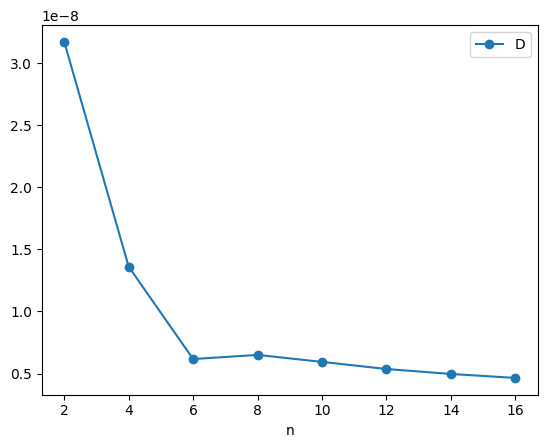

In [5]:
import joblib

import pandas as pd

diff_loaded = joblib.load('../data/processed/diffusion_extrap_place_holder_model.pkl')
df = pd.DataFrame({'n': [2, 4, 6, 8, 10, 12, 14, 16], 'temperature': [300] * 8})
df['D'] = diff_loaded.predict(df)
df.plot(x='n', y='D', marker='o')

## Adsorbtion

In [2]:
from itertools import product
import numpy as np
import pandas as pd

prssure = np.linspace(1, 50, 11)
temperature = np.linspace(300, 600, 11)
n = [2, 4, 6, 8, 10, 12, 14]
adsorption_type_num = [0, 1]  # 0 - absolute, 1 - excess

X_test = pd.DataFrame(list(product(prssure, temperature, n, adsorption_type_num)),
                      columns=['pressure_bar', 'temperature', 'n', 'adsorption_type_num'])
X_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1694 entries, 0 to 1693
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   pressure_bar         1694 non-null   float64
 1   temperature          1694 non-null   float64
 2   n                    1694 non-null   int64  
 3   adsorption_type_num  1694 non-null   int64  
dtypes: float64(2), int64(2)
memory usage: 53.1 KB


In [3]:
from kinetic_model.constants.adsorption import *

ads_model_loaded = joblib.load('../data/processed/knn_adsorption_slope_model.pkl')

X_test['adsorption'] = ads_model_loaded.predict(X_test)

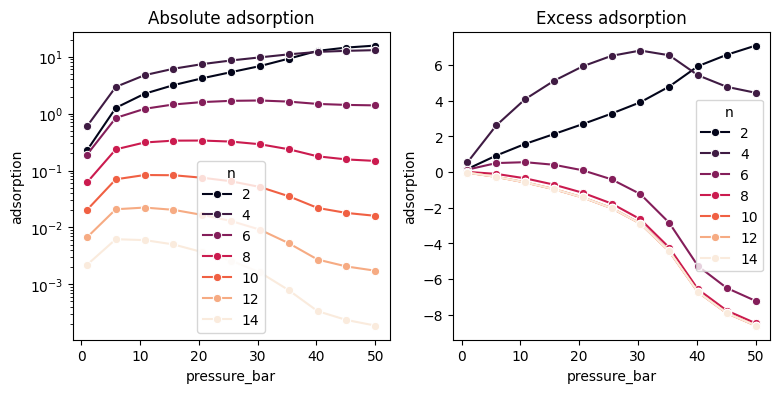

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(9, 4))

sns.lineplot(data=X_test.query('temperature==510 and adsorption_type_num==0'), x='pressure_bar', y='adsorption', hue='n', 
                palette='rocket', marker='o', ax=axs[0])

sns.lineplot(data=X_test.query('temperature==510 and adsorption_type_num==1'), x='pressure_bar', y='adsorption', hue='n', 
                palette='rocket', marker='o', ax=axs[1])

axs[0].set_title('Absolute adsorption')
axs[1].set_title('Excess adsorption')
axs[0].set_yscale('log')

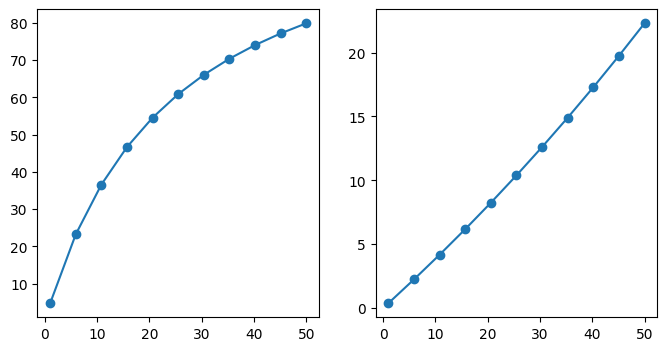

In [10]:
c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

pressures = np.linspace(1, 50, 11)
temperatures = [370] * pressures.shape[0]

C2_conc, C2_out_conc = c2_model.predict_absolute(pressures * 101325, temperatures), \
                c2_model.predict_out(pressures * 101325, temperatures)

fig, axs = plt.subplots(1, 2, figsize=(8, 4))
axs[0].plot(pressures, C2_conc, marker='o', label='C2 ads conc')
axs[1].plot(pressures, C2_out_conc, marker='o', label='C2 out conc')

# Examples of using Reaction class

{'A': [(('A', 'B'), -0.001)],
 'B': [(('A', 'B'), -0.001)],
 'C': [(('A', 'B'), 0.001)]}

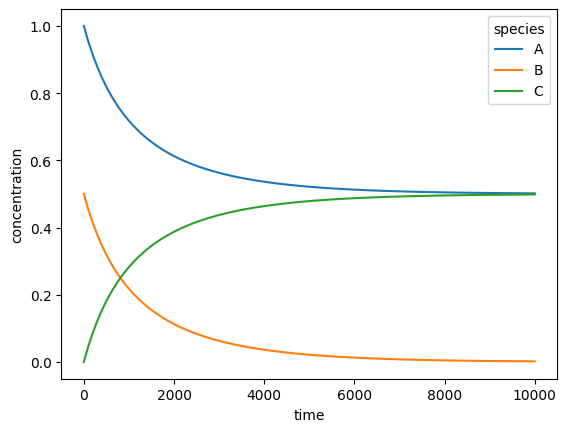

In [1]:
import numpy as np
import seaborn as sns
from kinetic_model.core.reactor import Reaction

# define a not reversible reaction: A + B -> C with k_forward=1e-3
reaction_list = [['A + B -> C', 1e-3]]
reactor = Reaction(reaction_list)
df = reactor.solve({'A': 1.0, 'B': .5, 'C': 0.0}, time_points=np.linspace(0, 10000, 100))
df['time'] = df.index
df = df.melt(id_vars='time', var_name='species', value_name='concentration')
sns.lineplot(data=df, x='time', y='concentration', hue='species')
reactor.reaction_dict

{'A': [(('A',), -0.1), (('B',), 0.05)], 'B': [(('A',), 0.1), (('B',), -0.05)]}

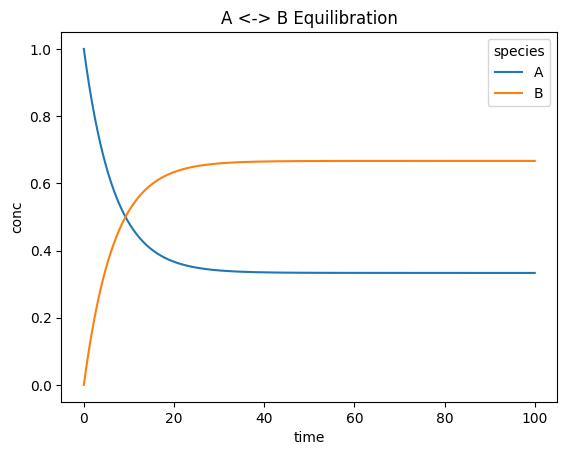

In [2]:
# define a reversible reaction: A <-> B with k_forward=0.1, k_backward=0.05
reaction_list = [['A <-> B', 0.1, 0.05]]
reactor = Reaction(reaction_list)

# simulate from t=0 to 100
time = np.linspace(0, 100, 500)
df_rev = reactor.solve({'A': 1.0, 'B': 0.0}, time)

# reshape and plot
df_rev['time'] = df_rev.index
dfm = df_rev.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm, x='time', y='conc', hue='species').set_title("A <-> B Equilibration")
reactor.reaction_dict

Text(0.5, 1.0, 'A+B→C→D Chain Dynamics')

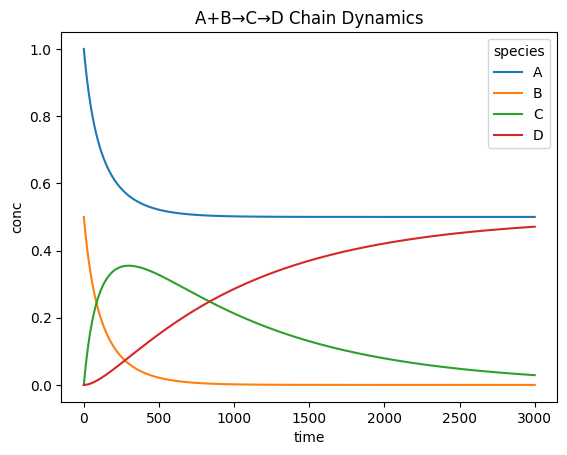

In [3]:
# two‐step network: A+B->C (k1), C->D (k2)
reaction_list = [
    ['A + B -> C', 1e-2],   # bimolecular
    ['C -> D',      1e-3]   # monomolecular
]
reactor = Reaction(reaction_list)

time = np.linspace(0, 3000, 1000)
initial = {'A':1.0, 'B':0.5, 'C':0.0, 'D':0.0}
df_net = reactor.solve(initial, time)

# plot all four species
df_net['time'] = df_net.index
dfm = df_net.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm, x='time', y='conc', hue='species')\
   .set_title("A+B→C→D Chain Dynamics")


Text(0.5, 1.0, 'With [B] Buffered at 0.5')

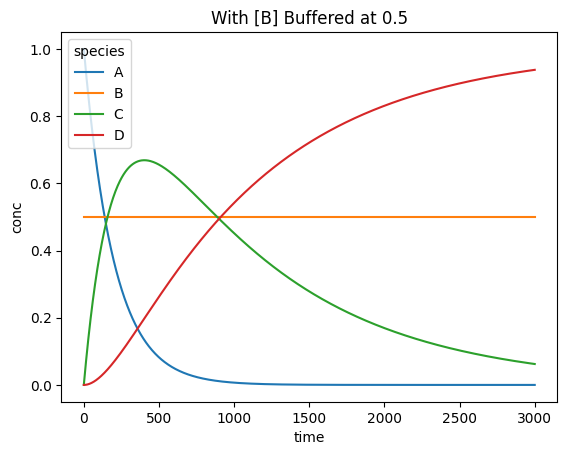

In [4]:
# same chain, but fix [B] = 0.5 throughout
reactor = Reaction(reaction_list, fixed_concentrations=['B'])
df_buf = reactor.solve({'A':1.0, 'B':0.5, 'C':0.0, 'D':0.0}, time)

# plot
df_buf['time'] = df_buf.index
dfm = df_buf.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm, x='time', y='conc', hue='species')\
   .set_title("With [B] Buffered at 0.5")


In [5]:
reactor.reaction_dict 

{'A': [(('A', 'B'), -0.01)],
 'B': [(('A', 'B'), -0.01)],
 'C': [(('A', 'B'), 0.01), (('C',), -0.001)],
 'D': [(('C',), 0.001)]}

Text(0.5, 1.0, 'With [B] Buffered at 0.5')

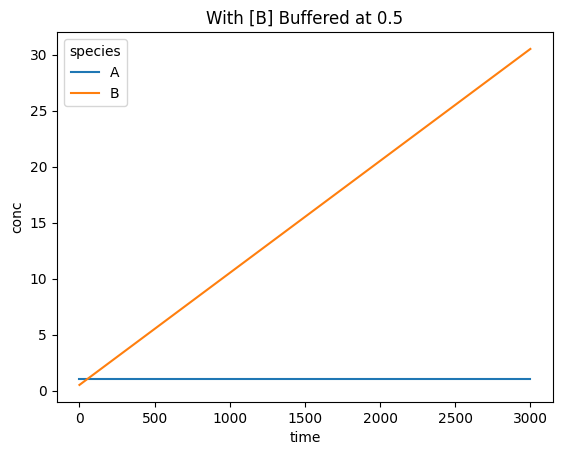

In [6]:
# simple example with fixed concentration of one species
reaction_list = [
    ['A -> B', 1e-2, 1e-2]   # monomolecular
]
reactor = Reaction(reaction_list, fixed_concentrations=['A'])
df_buf = reactor.solve({'A':1.0, 'B':0.5}, time)

# plot
df_buf['time'] = df_buf.index
dfm = df_buf.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm, x='time', y='conc', hue='species')\
   .set_title("With [B] Buffered at 0.5")

# Diffusion examples

Text(0.5, 1.0, 'Diffusion of X from A to B')

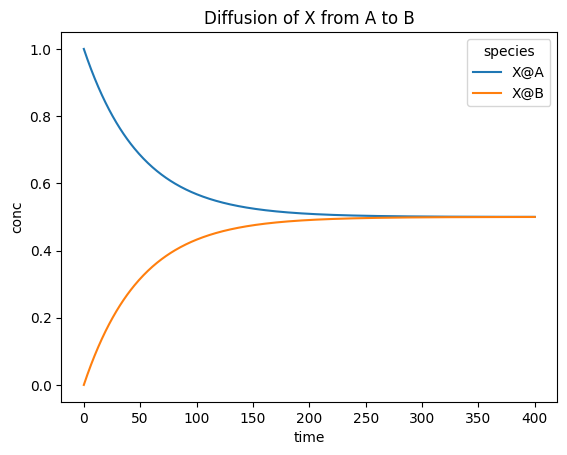

In [10]:
# In[1] — imports and setup
import numpy as np
import seaborn as sns
import pandas as pd
from kinetic_model.core.diffusion import Reaction_Diffusion

# define diffusion: X@A <D> X@B with rate k
# notation “X@A” means species X in compartment A
reaction_list = [['X@A <D> X@B', 1e-2, 1e-2]]
capacities = {'X@A': 1.0, 'X@B': 1.0}

reactor = Reaction_Diffusion(reactions=reaction_list,
                              capacity=capacities)

# time grid
time = np.linspace(0, 400, 500)

# start with all X in compartment A, none in B
initial = {'X@A': 1.0, 'X@B': 0.0}

# solve ODEs
df_diff = reactor.solve(initial_concs_dict=initial,
                        time_points=time)

# reshape for plotting
df_diff['time'] = df_diff.index
dfm = df_diff.melt(id_vars='time', var_name='species', value_name='conc')

# plot
sns.lineplot(data=dfm, x='time', y='conc', hue='species')\
   .set_title("Diffusion of X from A to B")


Text(0.5, 1.0, 'Diffusion with B twice the capacity of A')

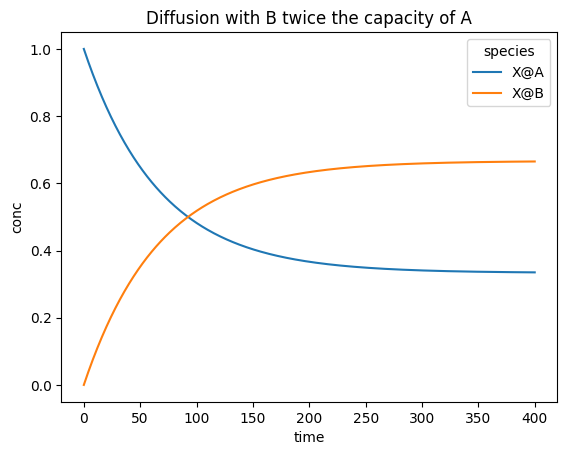

In [11]:
# In[2] — unequal capacities
capacities = {'X@A': 1.0, 'X@B': 2.0}
reactor = Reaction_Diffusion(reactions=reaction_list,
                             capacity=capacities)

# solve with same initial conditions and time grid
df_unequal = reactor.solve(initial, time)

# plot
df_unequal['time'] = df_unequal.index
dfm2 = df_unequal.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm2, x='time', y='conc', hue='species')\
   .set_title("Diffusion with B twice the capacity of A")


Text(0.5, 1.0, 'A→C in A plus C diffusing to B')

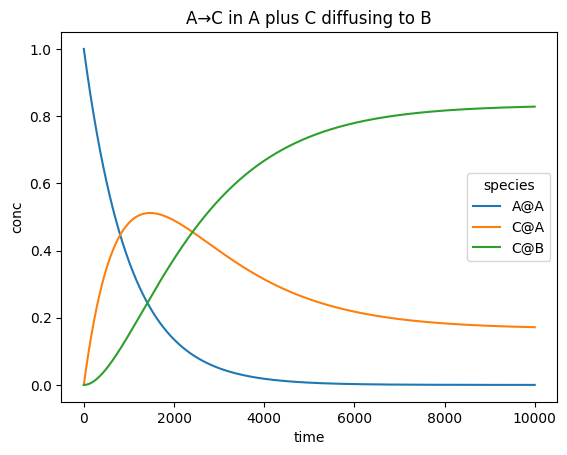

In [12]:
# In[3] — reaction plus diffusion
reaction_list = [
    ['A@A -> C@A',    1e-3],       # A→C in compartment A
    ['C@A <D> C@B',   5e-4, 2e-4]  # bidirectional diffusion of C
]
capacities = {'A@A':1.0, 'C@A':1.0, 'C@B':2.0}

reactor = Reaction_Diffusion(reactions=reaction_list,
                             capacity=capacities)

initial = {'A@A':1.0, 'C@A':0.0, 'C@B':0.0}

# time grid
time = np.linspace(0, 10000, 5000)

df_rxndiff = reactor.solve(initial, time)

# plot all three species
df_rxndiff['time'] = df_rxndiff.index
dfm3 = df_rxndiff.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm3, x='time', y='conc', hue='species')\
   .set_title("A→C in A plus C diffusing to B")


Text(0.5, 1.0, 'With C@B Buffered at 0 (always zero since no inflow)')

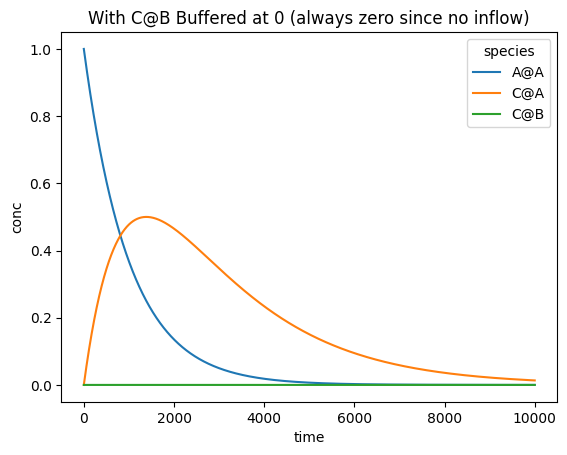

In [13]:
# In[4] — buffering C@B
reactor = Reaction_Diffusion(reactions=reaction_list,
                             capacity=capacities,
                             fixed_concentrations=['C@B'])

time = np.linspace(0, 10000, 5000)
df_buf = reactor.solve(initial, time)

df_buf['time'] = df_buf.index
dfm4 = df_buf.melt(id_vars='time', var_name='species', value_name='conc')
sns.lineplot(data=dfm4, x='time', y='conc', hue='species')\
   .set_title("With C@B Buffered at 0 (always zero since no inflow)")

# Energy profile 

In [14]:
import os, sys
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import display

sys.path.append(os.path.abspath(os.path.join('..', 'src')))

from kinetic_model.energy_profile.energy_processing import calculate_relative_energies, calculate_energies_with_references
from kinetic_model.energy_profile.energy_profile import EnergyProfile
import yaml
from collections import OrderedDict

In [24]:
temperatures = list(np.linspace(300, 600, 2))         # Can be varied
pressures = list(101325. * np.linspace(1, 50, 2))           # Can be carried
models = ['QM-QM_TPSSh-PBED3']   # Options: ['QM-QM_M06L-PBED3', 'QM-QM_TPPSh-PBED3]  
pathways = ['trigonal']         # Options: ['trigonal', 'hexagonal']
ref_struc = '1'                 # Choose either 1 or 5
energy_type = 'Gibbs free energy'   # Options: ['Electronic energy', 'Enthalpy', 'Gibbs free energy']
energy_unit = 'kJ/mol'              # Options: ['eV', 'kJ/mol', 'kcal/mol']

custom_order = ["1", "2", "3", "4", "5", "5a", "6", "1p", "7", "8", "9", "5p", "6p", "1pp", "10", "11", "12", "5pp", "6pp", "1ppp", "2-3", "3-4", "6-1p", "7-8", "8-9", "6p-1pp", "10-11", "11-12", "6pp-1ppp"]  # Use for sorting the intermediates in a table (or pd.DataFrame)

rel_results = calculate_relative_energies(
    structures_dir=os.path.abspath('../data/structures'),
    molecules_dir=os.path.abspath('../data/gas-phase-molecules'),
    temperatures=temperatures,
    models=models,
    ref_struc=ref_struc,
    pathways=pathways,
    pressures=pressures
)

columns_to_display = ['model', 'method', 'pathway', 'system', 'system_name', 'order', 'pressure', 'temperature', 'rel_E_eV', 'rel_H_eV', 'rel_G_eV']

# Filter only rows where 'order' is in the custom_order list
rel_results_filtered = rel_results[rel_results['order'].isin(custom_order)].copy()

# Assign the categorical order
rel_results_filtered['order'] = pd.Categorical(
    rel_results_filtered['order'], categories=custom_order, ordered=True
)

# Sort and select columns
rel_results_sorted = rel_results_filtered.sort_values(by='order')
formatted_df_tri = rel_results_sorted[columns_to_display]
dft = formatted_df_tri.query('temperature == 300 & pressure >= 1e5 & pressure <= 2e5')\
    .reset_index(drop=True).copy()
dft.head(5)

,model,method,pathway,system,system_name,order,pressure,temperature,rel_E_eV,rel_H_eV,rel_G_eV
0,QM-QM,TPSSh-PBED3,trigonal,Int_1_Ni-ethyl,Ni-ethyl,1,101325.0,300.0,0.0,0.0,0.0
1,QM-QM,TPSSh-PBED3,trigonal,Int_2_et-Ni-ethyl,et-Ni-ethyl,2,101325.0,300.0,-1.028972,-0.919356,-0.378867
2,QM-QM,TPSSh-PBED3,trigonal,Int_3_Ni-butyl,Ni-butyl,3,101325.0,300.0,-1.331717,-1.222829,-0.68827
3,QM-QM,TPSSh-PBED3,trigonal,Int_4_H-Ni-but,H-Ni-but,4,101325.0,300.0,-1.130121,-1.046452,-0.532723
4,QM-QM,TPSSh-PBED3,trigonal,Int_5_Ni-H,Ni-H,5,101325.0,300.0,-0.084445,-0.058671,-0.137015


In [23]:
add_energies = False # Add the energy of the plotted intermediates and TS
add_names = True    # Add the name of the plotted intermediates
energy_type='Gibbs free energy'
energy_unit = 'kJ/mol'

# This gives general settings for the plot
with open(os.path.abspath('./settings.yaml'), "r") as f:
            settings = yaml.safe_load(f)

# This gives more information on the sequences of intermediates to be plotted, the respective labels and colors
with open(os.path.abspath('./c8_energy_profiles_settings.yaml'), "r") as f:
            plot_settings = yaml.safe_load(f)
plot_settings['sequences'].append('1-->2-->3-->4-->5a-->6')
plot_settings['labels'].append('substitive pathway')
plot_settings['colors'].append("#E65100")
for key, value in plot_settings.items():
     value[-1], value[-2] = value[-2], value[-1]  # Swap last two entries to have the new pathway at the end



EP = EnergyProfile(
    dft,
    energy_type=energy_type, 
    energy_unit=energy_unit)

systems_ls = []
labels = []
for line in plot_settings['sequences']:
    systems = line.split(sep='-->')
    systems_ls.append(systems)
try:
    colors = plot_settings['colors']
except:
    colors = settings['color_palette'][1:]

position_map = OrderedDict()
for systems in systems_ls:
    for i, system in enumerate(systems):
        position = 2 * i
        if system not in position_map:
            position_map[system] = position
xmax = max(position_map.values()) + 1

EP.plot()
energy_values = []
for systems in systems_ls:
    tmp_values = EP.get_energy_range(systems)
    energy_values.extend(tmp_values)

ymin = min(energy_values)
ymax = max(energy_values)
yrange = ymax - ymin
padding = 0.10 * yrange

for i, systems in enumerate(systems_ls):
    for system in systems:
        position = position_map[system]

        if system == systems[0]:
            EP.add_level(system=system, 
                         position=position, 
                         label=plot_settings['labels'][i], 
                         color=colors[i])
        else:
            EP.add_level(system=system, 
                         position=position, 
                         color=colors[i])

        # EP.add_intermediate_energy_label(system=system, 
        #                                  position=position, 
        #                                  fontsize=18)

    for system1, system2 in zip(systems[:-1], systems[1:]):
        EP.add_connection(system1=system1, 
                          system2=system2, 
                          color=colors[i])
        # EP.add_ts_energy_label(system1=system1, 
        #                        system2=system2,
        #                        fontsize=18)
        
if add_energies:
    for i, systems in enumerate(systems_ls):
        for j, system in enumerate(systems):
            position = position_map[system]
            EP.add_intermediate_energy_label(system=system, 
                                               position=position, 
                                               fontsize=18)
        for system1, system2 in zip(systems[:-1], systems[1:]):
            EP.add_ts_energy_label(system1=system1, 
                                   system2=system2,
                                   fontsize=18)
if add_names:
    for i, systems in enumerate(systems_ls):
        for j, system in enumerate(systems):
            position = position_map[system]
            EP.add_structure_name(system=system,
                                  position=position, 
                                  fontsize=18)
     
EP.show(xmin=0,
        xmax=xmax,
        ymin=ymin,
        ymax=ymax,
        padding=padding,
        legend=True)
